# Intelligent Driver Activity Monitoring & Safety Agent
## Comprehensive Exploratory Data Analysis (EDA) & Kinematic Telemetry Audit

**Academic Project:** B.Tech Capstone / Mini-Project  
**Repository:** `yeswanth225/driver-machine-learning-model`  
**Focus:** Multimodal Telematics, Sensor Kinematics, Behavioral Labeling & Data Quality Diagnostics

---

### Executive Overview & Problem Statement

Road traffic incidents remain one of the primary causes of worldwide preventable injuries and fatalities. Modern telematics systems seek to transition from *post-crash notification* to *real-time preemptive risk mitigation*. The **Intelligent Driver Activity Monitoring & Safety Agent** is an academic engineering framework designed to ingest continuous vehicular kinematic telemetry, classify driver behavioral states and hazardous maneuvers, and dynamically evaluate road risk through a deterministic, explainable safety agent.

The system decouples vehicle motion telemetry into two specialized, late-fused machine learning pipelines:
1. **Pipeline A (Driving Behaviour Classification):** Evaluates overall driver stylistic aggression (*Normal* vs. *Aggressive* driving) using causal longitudinal/lateral acceleration, speed profiles, and rolling statistical distributions.
2. **Pipeline B (Sudden Maneuver Detection):** Detects acute, transient risky maneuvers (*Sudden Acceleration [SA]*, *Sudden Deceleration [SD]*, *Sudden Right Turn [SRT]*, *Sudden Left Turn [SLT]*) using high-rate IMU kinematics and a kinematic event gate.

### Objectives of this Exploratory Data Analysis
Before training machine learning algorithms, a rigorous exploratory data analysis is essential to:
- Establish the baseline statistical properties and sensor signal distributions of the available vehicular datasets.
- Assess data quality, sampling frequency jitter, missing observations, and sensor clipping.
- Investigate class distributions, label balance, and session-dependent characteristics.
- Uncover critical physical and informational pathologies (including sensor mount orientation shifts, temporal autocorrelation, and episode-level clustering).
- Prevent subtle forms of data leakage (such as anti-causal rolling lookahead or cross-partition window bleeding) prior to model evaluation.


## Section 2: Environment Setup & Library Imports

We import standard data science, signal processing, and statistical visualization libraries. We set reproducible seeds and establish clean, high-contrast visualization defaults suitable for academic publication and viva demonstration.


In [1]:
import os
import sys
import json
import glob
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy import stats, signal

# Configure Matplotlib & Seaborn styles for professional academic presentation
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#27272a'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#e5e7eb'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.autolayout'] = True

# Repository root resolution
REPO_ROOT = Path('.').resolve()
if not (REPO_ROOT / 'dataset').exists() and (REPO_ROOT.parent / 'dataset').exists():
    REPO_ROOT = REPO_ROOT.parent

print(f"Repository Root: {REPO_ROOT}")
print(f"Python Version: {sys.version.split()[0]}")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version: {np.__version__}")


Repository Root: D:\driver ml model\driver-monitoring-agent
Python Version: 3.11.0
Pandas Version: 2.2.2
NumPy Version: 2.4.6


## Section 3: Dataset Inventory & Multi-Dataset Extraction

The project repository organizes vehicular telematics data into multiple tiers across `dataset/raw/` and `dataset/processed/`. The table below surveys the available data tiers:

| Dataset ID | Academic Source / Citation | Modality | Ground-Truth Labels | Sampling Rate | Role in Project |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Dataset C** | Mendeley Data (5stn873wft.1) | Phone Accel, Gyro, Speed | **Binary: Normal vs Aggressive** | 10 Hz nominal | **Primary for Pipeline A** |
| **Dataset B** | Mendeley Data (jj3tw8kj6h.3) | Raspberry Pi 6-DOF IMU | **4-Class: SA, SD, SRT, SLT** | 10 Hz (100 Hz raw) | **Primary for Pipeline B** |
| **Dataset A1** | Mendeley Data (9vr83n7z5j.2) | Phone Accel, Gyro, Pressure | Unsupervised / 7 Drivers | 100 Hz nominal | Driver Identification / Auxiliary |
| **Dataset A2** | Mendeley Data (9vr83n7z5j.2) | Phone Accel, Gyro (Daywise) | Naturalistic / 16 Trips | 100 Hz nominal | Long-Duration Auxiliary |
| **Dataset F** | Kaggle (yotamkatz) | OBD-II Telematics (4 Drivers) | 4 Drivers / Naturalistic | 1 Hz | Cross-Modal Auxiliary |
| **Dataset G** | Kaggle (vitorrf) | OBD-II / CAN Telematics | 229 Trips / Large-Scale | Variable | Pattern Mining Auxiliary |


In [2]:
# Inspect and catalogue available datasets in the repository
dataset_inventory = []

def get_dir_size_mb(path):
    total = 0
    if path.is_file():
        return round(path.stat().st_size / (1024 * 1024), 2)
    for p in path.glob('**/*'):
        if p.is_file():
            total += p.stat().st_size
    return round(total / (1024 * 1024), 2)

checks = [
    ('Dataset C (Pipeline A Processed)', REPO_ROOT / 'dataset/processed/dataset_c_processed_all.csv', 'Processed CSV'),
    ('Dataset C (Pipeline A Train)', REPO_ROOT / 'dataset/processed/dataset_c_train.csv', 'Train Split CSV'),
    ('Dataset C (Pipeline A Test)', REPO_ROOT / 'dataset/processed/dataset_c_test.csv', 'Test Split CSV'),
    ('Dataset B (Pipeline B Processed)', REPO_ROOT / 'dataset/processed/dataset_b_processed_all.csv', 'Processed CSV'),
    ('Dataset B (Pipeline B Event Feats)', REPO_ROOT / 'dataset/processed/dataset_b_event_features.csv', 'Event Features CSV'),
    ('Dataset B (Raw Sensor Log)', REPO_ROOT / 'dataset/raw/dataset_02_jj3tw8kj6h/jj3tw8kj6h-3/sensor_raw.csv', 'Raw Time-Series CSV'),
    ('Dataset A1 (Driver 1 Accel)', REPO_ROOT / 'dataset/raw/drivers/Driver-1/Accelerometer.csv', 'High-Rate IMU CSV'),
    ('Dataset F (OBD Telematics)', REPO_ROOT / 'dataset/raw/dataset_06_yotamkatz/driver_E.csv', '1 Hz OBD-II CSV'),
]

for name, path, dtype in checks:
    exists = path.exists()
    size_mb = get_dir_size_mb(path) if exists else 0.0
    dataset_inventory.append({
        'Dataset': name,
        'Path': str(path.relative_to(REPO_ROOT)),
        'Format': dtype,
        'Exists': exists,
        'Size (MB)': size_mb
    })

inventory_df = pd.DataFrame(dataset_inventory)
display(inventory_df)


,Dataset,Path,Format,Exists,Size (MB)
0,Dataset C (Pipeline A Processed),dataset\processed\dataset_c_processed_all.csv,Processed CSV,True,11.31
1,Dataset C (Pipeline A Train),dataset\processed\dataset_c_train.csv,Train Split CSV,True,7.99
2,Dataset C (Pipeline A Test),dataset\processed\dataset_c_test.csv,Test Split CSV,True,1.75
3,Dataset B (Pipeline B Processed),dataset\processed\dataset_b_processed_all.csv,Processed CSV,True,1.19
4,Dataset B (Pipeline B Event Feats),dataset\processed\dataset_b_event_features.csv,Event Features CSV,True,0.19
5,Dataset B (Raw Sensor Log),dataset\raw\dataset_02_jj3tw8kj6h\jj3tw8kj6h-3...,Raw Time-Series CSV,True,0.13
6,Dataset A1 (Driver 1 Accel),dataset\raw\drivers\Driver-1\Accelerometer.csv,High-Rate IMU CSV,True,6.20
7,Dataset F (OBD Telematics),dataset\raw\dataset_06_yotamkatz\driver_E.csv,1 Hz OBD-II CSV,True,1.06


In [3]:
# Load primary datasets C and B
df_c = pd.read_csv(REPO_ROOT / 'dataset/processed/dataset_c_processed_all.csv')
print(f"Dataset C Loaded Successfully: {df_c.shape[0]:,} rows x {df_c.shape[1]} columns")

df_b_raw = pd.read_csv(REPO_ROOT / 'dataset/raw/dataset_02_jj3tw8kj6h/jj3tw8kj6h-3/sensor_raw.csv')
print(f"Dataset B Raw Loaded Successfully: {df_b_raw.shape[0]:,} rows x {df_b_raw.shape[1]} columns")

df_b_events = pd.read_csv(REPO_ROOT / 'dataset/processed/dataset_b_event_features.csv')
print(f"Dataset B Events Loaded Successfully: {df_b_events.shape[0]:,} events x {df_b_events.shape[1]} features")


Dataset C Loaded Successfully: 13,840 rows x 50 columns


Dataset B Raw Loaded Successfully: 1,114 rows x 12 columns
Dataset B Events Loaded Successfully: 109 events x 97 features


In [4]:
print("Dataset C (Pipeline A) - First 5 Records:")
display(df_c[['Acc X', 'Acc Y', 'Acc Z', 'gyro_x', 'gyro_y', 'gyro_z', 'label', 'session']].head())

print("Dataset C (Pipeline A) - Last 5 Records:")
display(df_c[['Acc X', 'Acc Y', 'Acc Z', 'gyro_x', 'gyro_y', 'gyro_z', 'label', 'session']].tail())


Dataset C (Pipeline A) - First 5 Records:


,Acc X,Acc Y,Acc Z,gyro_x,gyro_y,gyro_z,label,session
0,0.046402,-0.137178,-0.282934,-0.036306,-0.008226,-0.023416,0,session_1
1,-0.136978,0.365242,0.108889,0.035776,-0.009448,0.009570,0,session_1
2,-0.045355,-0.103340,-0.534985,-0.011871,-0.027774,0.003462,0,session_1
3,0.242089,0.072761,-0.350396,-0.017980,0.002769,-0.005091,0,session_1
4,-0.230234,0.011765,-0.494085,0.011342,0.003380,0.006516,0,session_1


Dataset C (Pipeline A) - Last 5 Records:


,Acc X,Acc Y,Acc Z,gyro_x,gyro_y,gyro_z,label,session
13835,0.551813,0.443052,-0.714437,-0.114008,0.073161,-0.048605,1,session_2
13836,-0.255498,-0.540867,1.586697,0.238461,-0.209058,-0.007066,1,session_2
13837,-1.276934,0.548246,-0.201897,0.102849,0.081103,-0.092587,1,session_2
13838,-0.436406,-0.219264,0.397958,-0.051089,-0.001975,-0.058989,1,session_2
13839,-0.436406,-0.219264,0.397958,-0.001609,0.024903,0.000876,1,session_2


In [5]:
print("Dataset B (Pipeline B Raw) - First 5 Records:")
display(df_b_raw[['Hour', 'Minute', 'Second', 'AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ', 'Class', 'DriverID']].head())

print("Dataset B (Pipeline B Raw) - Last 5 Records:")
display(df_b_raw[['Hour', 'Minute', 'Second', 'AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ', 'Class', 'DriverID']].tail())


Dataset B (Pipeline B Raw) - First 5 Records:


,Hour,Minute,Second,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,Class,DriverID
0,15,39,39,0.226807,-0.132324,-1.010498,-0.496183,2.511450,0.702290,3,Driver-1
1,15,39,40,0.331299,-0.145752,-0.998291,-1.519084,2.832061,-1.244275,3,Driver-1
2,15,39,41,0.431396,-0.209717,-1.004150,0.679389,3.206107,-0.229008,3,Driver-1
3,15,39,42,0.370117,-0.062012,-0.901123,0.053435,9.244275,2.893130,3,Driver-1
4,15,39,42,0.364990,-0.132324,-1.001221,-0.664122,8.030534,0.961832,3,Driver-1


Dataset B (Pipeline B Raw) - Last 5 Records:


,Hour,Minute,Second,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,Class,DriverID
1109,12,26,27,0.472900,-0.431152,-0.873535,-1.961832,2.358779,8.893130,4,Driver-3
1110,12,26,28,0.459961,-0.227051,-0.967041,-0.435115,5.396947,1.282443,4,Driver-3
1111,12,26,29,0.419189,-0.192871,-1.002686,-1.061069,4.534351,1.183206,4,Driver-3
1112,12,26,30,0.308838,-0.090088,-1.023193,-1.015267,5.259542,0.656489,4,Driver-3
1113,12,26,31,0.098145,-0.015869,-1.001221,-0.877863,4.488550,0.045802,4,Driver-3


## Section 4: Comprehensive Data Quality & Signal Integrity Analysis

Before performing domain-specific behavioral analysis, we rigorously inspect both datasets for missing values, duplicates, infinite values, feature ranges, and sampling jitter.


In [6]:
# Data Quality Audit for Dataset C & Dataset B
quality_summary = []

for name, df in [('Dataset C (Driving Style)', df_c), ('Dataset B (Raw Maneuvers)', df_b_raw)]:
    null_count = int(df.isnull().sum().sum())
    inf_count = int(np.isinf(df.select_dtypes(include=np.number)).sum().sum())
    dup_count = int(df.duplicated().sum())
    
    quality_summary.append({
        'Dataset': name,
        'Total Rows': len(df),
        'Total Columns': len(df.columns),
        'Missing Values': null_count,
        'Infinite Values': inf_count,
        'Duplicate Rows': dup_count,
        'Data Quality Status': 'EXCELLENT' if (null_count == 0 and inf_count == 0 and dup_count == 0) else 'REQUIRES_CLEANING'
    })

quality_df = pd.DataFrame(quality_summary)
display(quality_df)


,Dataset,Total Rows,Total Columns,Missing Values,Infinite Values,Duplicate Rows,Data Quality Status
0,Dataset C (Driving Style),13840,50,0,0,0,EXCELLENT
1,Dataset B (Raw Maneuvers),1114,12,0,0,0,EXCELLENT


In [7]:
# Summary statistics of raw sensor channels
print("Dataset C - Physical Sensor Channels Summary (m/s^2 and rad/s):")
display(df_c[['Acc X', 'Acc Y', 'Acc Z', 'gyro_x', 'gyro_y', 'gyro_z']].describe().T)

print("\nDataset B Raw - Physical Sensor Channels Summary (g and deg/s raw):")
display(df_b_raw[['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ']].describe().T)


Dataset C - Physical Sensor Channels Summary (m/s^2 and rad/s):


,count,mean,std,min,25%,50%,75%,max
Acc X,13840.0,-0.000263,1.022784,-8.805807,-0.373291,-0.013724,0.357708,10.488632
Acc Y,13840.0,0.179818,0.829451,-8.476646,-0.123669,0.166934,0.474471,11.013258
Acc Z,13840.0,-0.029545,1.750384,-17.320633,-0.696590,-0.028444,0.663439,19.725800
gyro_x,13840.0,-0.001173,0.139827,-2.062668,-0.046080,-0.002219,0.044817,1.611687
gyro_y,13840.0,-0.006504,0.087506,-0.571912,-0.032661,-0.005783,0.021238,0.599585
gyro_z,13840.0,-0.002894,0.067357,-0.666047,-0.026613,-0.002179,0.023620,0.542856



Dataset B Raw - Physical Sensor Channels Summary (g and deg/s raw):


,count,mean,std,min,25%,50%,75%,max
AccX,1114.0,0.252417,0.183155,-0.252686,0.132202,0.244507,0.372559,0.747803
AccY,1114.0,-0.095110,0.190407,-0.793457,-0.179077,-0.102295,-0.023010,0.768555
AccZ,1114.0,-0.983215,0.098061,-1.367920,-1.031372,-0.986938,-0.928223,-0.456787
GyroX,1114.0,-0.829957,3.404297,-14.946565,-2.274809,-0.698473,0.784351,12.778626
GyroY,1114.0,4.122309,3.252790,-10.351145,2.610687,4.290076,5.761450,16.793893
GyroZ,1114.0,1.076404,12.049384,-50.259542,0.282443,0.961832,1.992366,45.442748


## Section 5: Dataset C (Pipeline A — Driving Behaviour Classification) Deep-Dive EDA

Dataset C was collected by researchers at the University of Porto via an Android smartphone mounted inside a vehicle. The supervised task is binary driving habit classification:
- **`label = 0`**: **Normal Driving** (smooth highway cruising, gentle stops, nominal lane transitions).
- **`label = 1`**: **Aggressive Driving** (abrupt throttle applications, harsh braking, high-speed cornering).

### 5.1 Overall Class Distribution & Class Imbalance
We first evaluate the overall proportion of Normal versus Aggressive driving samples.


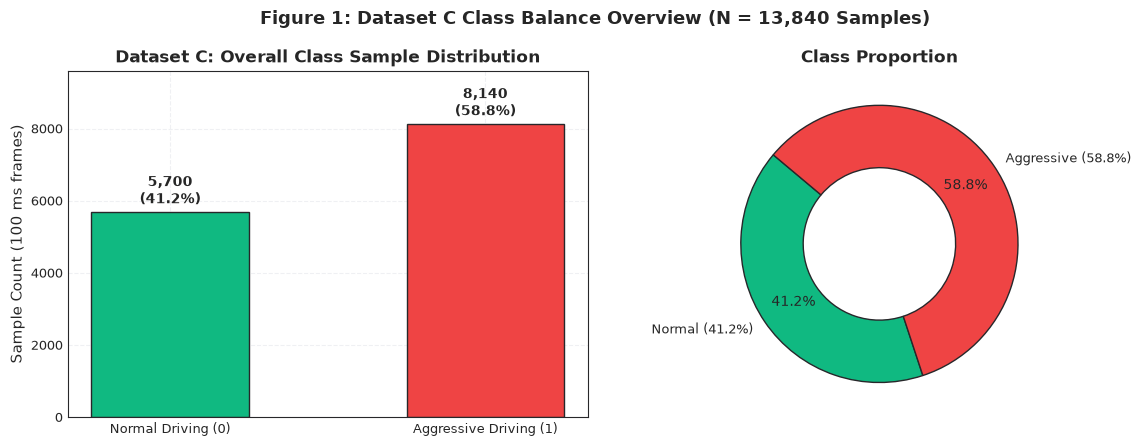

Normal Driving Samples (0):     5,700 (41.18%)
Aggressive Driving Samples (1): 8,140 (58.82%)
Total Telemetry Frames:         13,840 frames (~23.06 minutes total)


In [8]:
# Class distribution analysis
class_counts = df_c['label'].value_counts().sort_index()
class_pcts = (class_counts / len(df_c)) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Bar chart
colors = ['#10b981', '#ef4444']
bars = axes[0].bar(['Normal Driving (0)', 'Aggressive Driving (1)'], class_counts.values, color=colors, width=0.5, edgecolor='#27272a')
for bar, count, pct in zip(bars, class_counts.values, class_pcts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, f"{count:,}\n({pct:.1f}%)", 
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('Dataset C: Overall Class Sample Distribution', fontweight='bold')
axes[0].set_ylabel('Sample Count (100 ms frames)')
axes[0].set_ylim(0, max(class_counts.values) * 1.18)

# Donut chart
axes[1].pie(class_counts.values, labels=['Normal (41.2%)', 'Aggressive (58.8%)'], colors=colors, 
            autopct='%1.1f%%', startangle=140, pctdistance=0.75, wedgeprops=dict(width=0.45, edgecolor='#27272a'))
axes[1].set_title('Class Proportion', fontweight='bold')

plt.suptitle('Figure 1: Dataset C Class Balance Overview (N = 13,840 Samples)', fontsize=13, fontweight='bold')
plt.show()

print(f"Normal Driving Samples (0):     {class_counts[0]:,} ({class_pcts[0]:.2f}%)")
print(f"Aggressive Driving Samples (1): {class_counts[1]:,} ({class_pcts[1]:.2f}%)")
print(f"Total Telemetry Frames:         {len(df_c):,} frames (~23.06 minutes total)")


### 5.2 Session-Wise Class Distribution & Prior Mismatch Pathology

Dataset C is not a single continuous homogeneous trip; it consists of two distinct recording sessions separated by **1 hour, 17 minutes, and 37 seconds** of non-recording time:
- **Session 1:** Recorded 2021-03-17 17:15:15 to 17:27:35 ($N = 7,399$ rows).
- **Session 2:** Recorded 2021-03-17 18:45:12 to 18:55:56 ($N = 6,441$ rows).

We examine the class prior within each session:


Cross-Tabulation of Samples by Session and Label:


label,0,1,All
session,,,
session_1,3563,3836,7399
session_2,2137,4304,6441
All,5700,8140,13840



Percentage Distribution by Session (%):


label,0,1
session,,
session_1,48.16,51.84
session_2,33.18,66.82


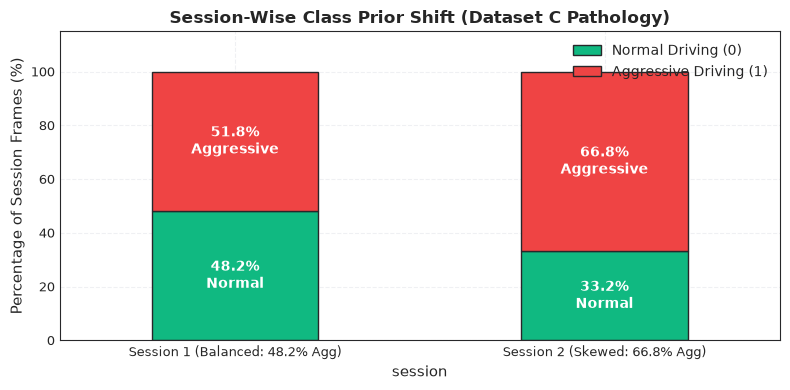

In [9]:
session_class_ct = pd.crosstab(df_c['session'], df_c['label'], margins=True)
session_class_pct = pd.crosstab(df_c['session'], df_c['label'], normalize='index') * 100

print("Cross-Tabulation of Samples by Session and Label:")
display(session_class_ct)

print("\nPercentage Distribution by Session (%):")
display(session_class_pct.round(2))

# Visualizing session prior shift
fig, ax = plt.subplots(figsize=(8, 4))
session_class_pct.drop('All', errors='ignore').plot(kind='bar', stacked=True, color=['#10b981', '#ef4444'], ax=ax, edgecolor='#27272a', width=0.45)
ax.set_title('Session-Wise Class Prior Shift (Dataset C Pathology)', fontweight='bold')
ax.set_ylabel('Percentage of Session Frames (%)')
ax.set_xticklabels(['Session 1 (Balanced: 48.2% Agg)', 'Session 2 (Skewed: 66.8% Agg)'], rotation=0)
ax.legend(['Normal Driving (0)', 'Aggressive Driving (1)'], loc='upper right')
ax.set_ylim(0, 115)

for i, (idx, row) in enumerate(session_class_pct.drop('All', errors='ignore').iterrows()):
    ax.text(i, row[0]/2, f"{row[0]:.1f}%\nNormal", ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    ax.text(i, row[0] + row[1]/2, f"{row[1]:.1f}%\nAggressive", ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.show()


### 5.3 Sensor Feature Distributions: Normal vs. Aggressive

We visualize the distribution of physical sensor signals (triaxial acceleration and gyroscope angular velocities) grouped by driving style.


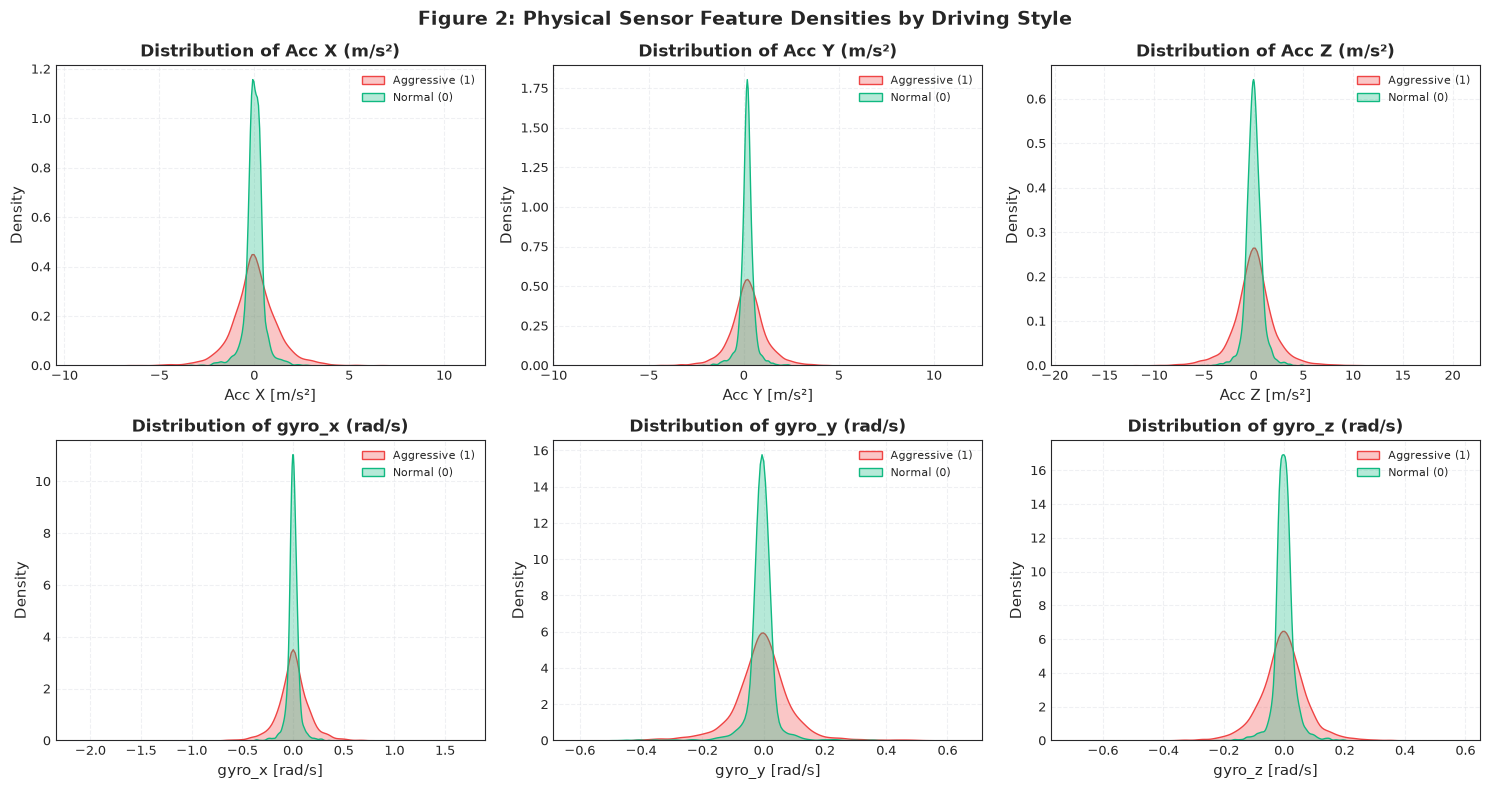

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

features = [('Acc X', 'm/s²'), ('Acc Y', 'm/s²'), ('Acc Z', 'm/s²'), 
            ('gyro_x', 'rad/s'), ('gyro_y', 'rad/s'), ('gyro_z', 'rad/s')]

for i, (col, unit) in enumerate(features):
    sns.kdeplot(data=df_c, x=col, hue='label', palette=['#10b981', '#ef4444'], common_norm=False, fill=True, alpha=0.3, ax=axes[i])
    axes[i].set_title(f"Distribution of {col} ({unit})", fontweight='bold')
    axes[i].set_xlabel(f"{col} [{unit}]")
    axes[i].legend(['Aggressive (1)', 'Normal (0)'], loc='upper right', fontsize=8)

plt.suptitle('Figure 2: Physical Sensor Feature Densities by Driving Style', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 5.4 Correlation Heatmap & Multi-Collinearity

We compute the Pearson correlation matrix across the core causal kinematic features to identify coupling between orthogonal axes and rolling statistical metrics.


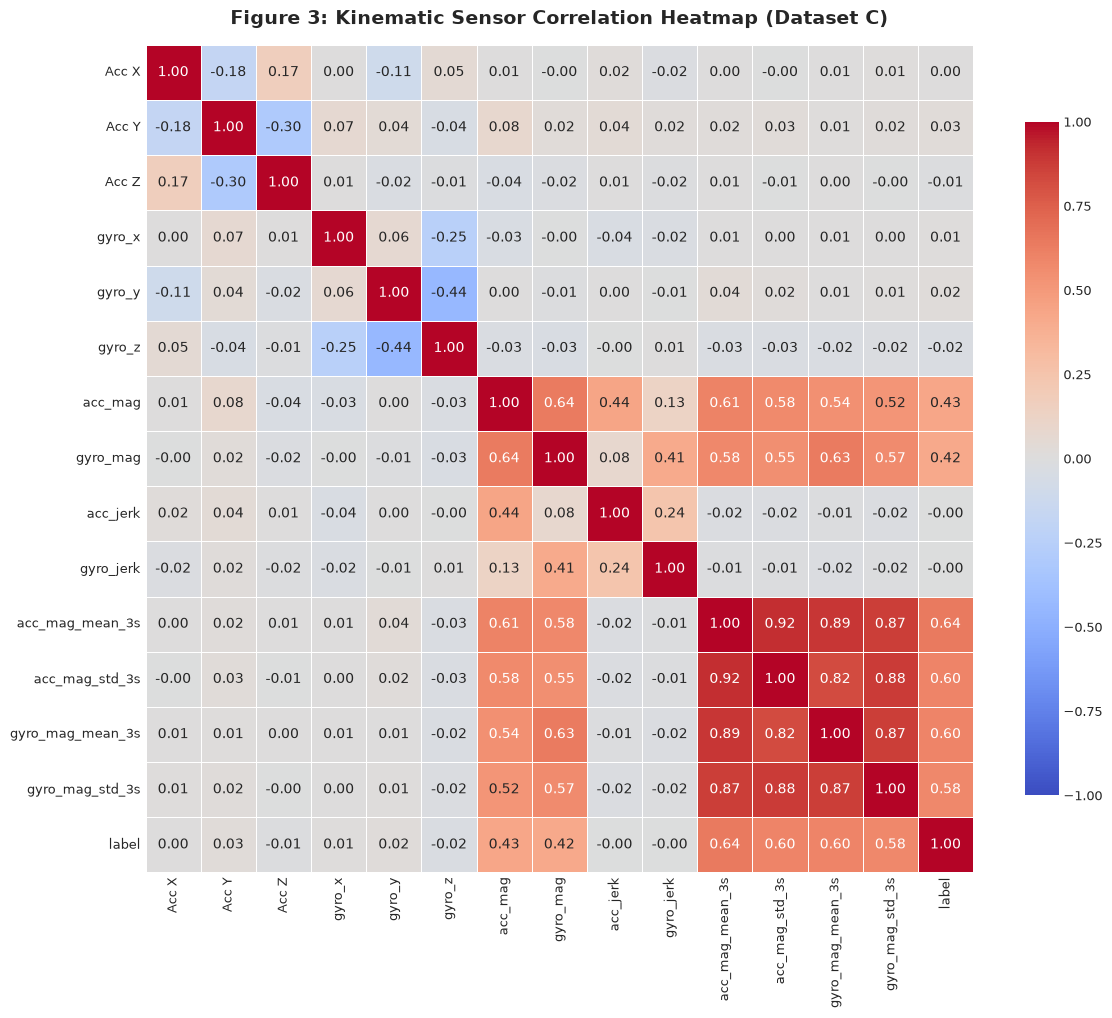

In [11]:
# Select core features for correlation heatmap
heatmap_cols = ['Acc X', 'Acc Y', 'Acc Z', 'gyro_x', 'gyro_y', 'gyro_z', 
                'acc_mag', 'gyro_mag', 'acc_jerk', 'gyro_jerk',
                'acc_mag_mean_3s', 'acc_mag_std_3s', 'gyro_mag_mean_3s', 'gyro_mag_std_3s', 'label']

valid_cols = [c for c in heatmap_cols if c in df_c.columns]
corr_matrix = df_c[valid_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1.0, vmax=1.0, 
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Figure 3: Kinematic Sensor Correlation Heatmap (Dataset C)', fontsize=14, fontweight='bold', pad=15)
plt.show()


### 5.5 Time-Series Inspection: Normal Cruising vs. Aggressive Maneuvers

We plot a continuous 60-second window comparing acceleration and gyroscope waveforms during smooth highway driving versus an aggressive maneuver sequence.


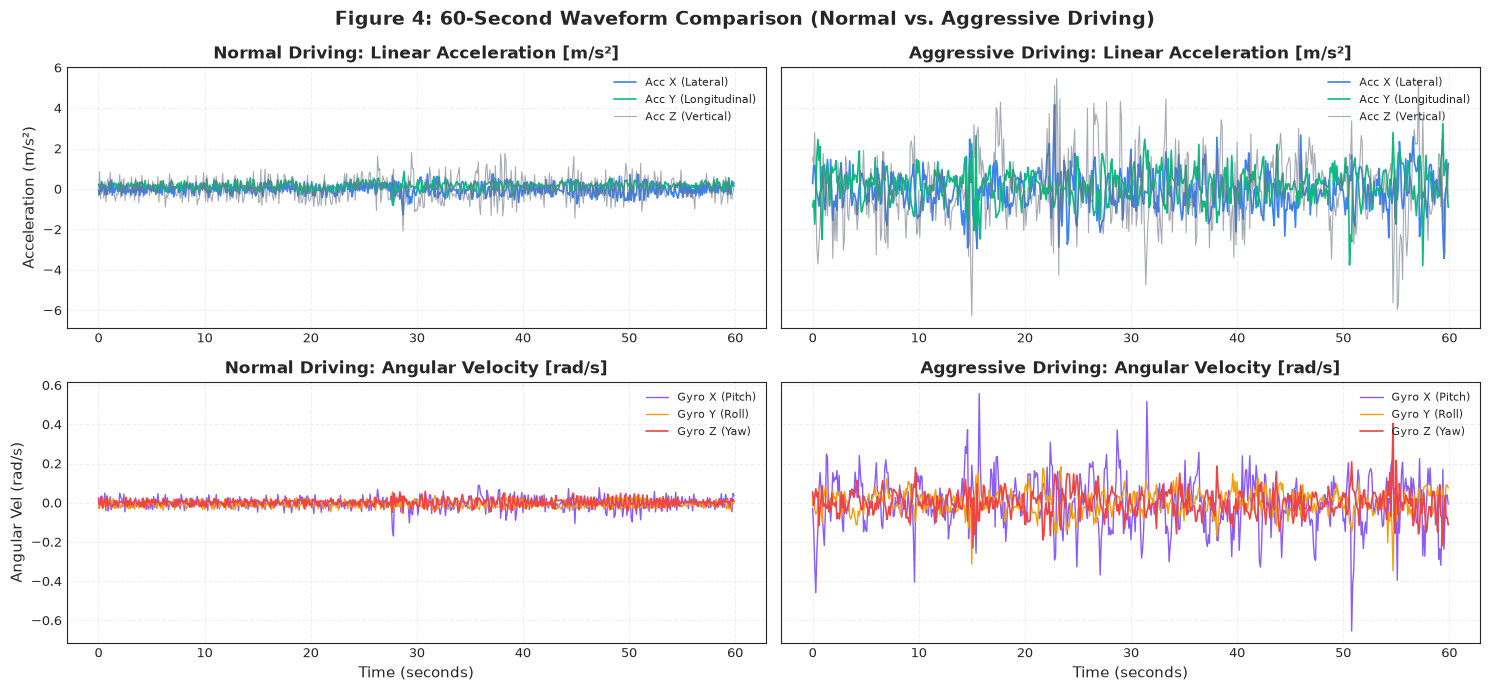

In [12]:
# Extract representative 60-second clips
normal_clip = df_c[df_c['label'] == 0].iloc[1000:1600].reset_index(drop=True)
aggr_clip = df_c[df_c['label'] == 1].iloc[1000:1600].reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharey='row')

# Normal clip Accel & Gyro
time_axis = np.arange(len(normal_clip)) * 0.1
axes[0, 0].plot(time_axis, normal_clip['Acc X'], label='Acc X (Lateral)', color='#3b82f6', lw=1.2)
axes[0, 0].plot(time_axis, normal_clip['Acc Y'], label='Acc Y (Longitudinal)', color='#10b981', lw=1.2)
axes[0, 0].plot(time_axis, normal_clip['Acc Z'], label='Acc Z (Vertical)', color='#6b7280', lw=0.8, alpha=0.6)
axes[0, 0].set_title('Normal Driving: Linear Acceleration [m/s²]', fontweight='bold')
axes[0, 0].set_ylabel('Acceleration (m/s²)')
axes[0, 0].legend(loc='upper right', fontsize=8)

axes[1, 0].plot(time_axis, normal_clip['gyro_x'], label='Gyro X (Pitch)', color='#8b5cf6', lw=1.0)
axes[1, 0].plot(time_axis, normal_clip['gyro_y'], label='Gyro Y (Roll)', color='#f59e0b', lw=1.0)
axes[1, 0].plot(time_axis, normal_clip['gyro_z'], label='Gyro Z (Yaw)', color='#ef4444', lw=1.2)
axes[1, 0].set_title('Normal Driving: Angular Velocity [rad/s]', fontweight='bold')
axes[1, 0].set_xlabel('Time (seconds)')
axes[1, 0].set_ylabel('Angular Vel (rad/s)')
axes[1, 0].legend(loc='upper right', fontsize=8)

# Aggressive clip Accel & Gyro
axes[0, 1].plot(time_axis, aggr_clip['Acc X'], label='Acc X (Lateral)', color='#3b82f6', lw=1.2)
axes[0, 1].plot(time_axis, aggr_clip['Acc Y'], label='Acc Y (Longitudinal)', color='#10b981', lw=1.2)
axes[0, 1].plot(time_axis, aggr_clip['Acc Z'], label='Acc Z (Vertical)', color='#6b7280', lw=0.8, alpha=0.6)
axes[0, 1].set_title('Aggressive Driving: Linear Acceleration [m/s²]', fontweight='bold')
axes[0, 1].legend(loc='upper right', fontsize=8)

axes[1, 1].plot(time_axis, aggr_clip['gyro_x'], label='Gyro X (Pitch)', color='#8b5cf6', lw=1.0)
axes[1, 1].plot(time_axis, aggr_clip['gyro_y'], label='Gyro Y (Roll)', color='#f59e0b', lw=1.0)
axes[1, 1].plot(time_axis, aggr_clip['gyro_z'], label='Gyro Z (Yaw)', color='#ef4444', lw=1.2)
axes[1, 1].set_title('Aggressive Driving: Angular Velocity [rad/s]', fontweight='bold')
axes[1, 1].set_xlabel('Time (seconds)')
axes[1, 1].legend(loc='upper right', fontsize=8)

plt.suptitle('Figure 4: 60-Second Waveform Comparison (Normal vs. Aggressive Driving)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 5.6 Physical Mounting Tilt Drift: 31.36° Static Angular Offset

A critical forensic finding in this research is that the smartphone was remounted at a substantially different physical tilt between the two trips. We calculate the static acceleration vector for each session and determine the physical mounting angle divergence:

$$ec{a}_1 = \mathbb{E}[ec{a}_{	ext{Session 1}}], \quad ec{a}_2 = \mathbb{E}[ec{a}_{	ext{Session 2}}]$$
$$\cos 	heta = rac{ec{a}_1 \cdot ec{a}_2}{\|ec{a}_1\| \|ec{a}_2\|} \implies 	heta = rccos(\cos 	heta)$$


In [13]:
# Compute static acceleration vectors per session
s1 = df_c[df_c['session'] == 'session_1']
s2 = df_c[df_c['session'] == 'session_2']

a1 = np.array([s1['Acc X'].mean(), s1['Acc Y'].mean(), s1['Acc Z'].mean()])
a2 = np.array([s2['Acc X'].mean(), s2['Acc Y'].mean(), s2['Acc Z'].mean()])

mag1 = np.linalg.norm(a1)
mag2 = np.linalg.norm(a2)

dot_prod = np.dot(a1, a2)
cos_theta = dot_prod / (mag1 * mag2)
theta_rad = math.acos(cos_theta)
theta_deg = math.degrees(theta_rad)

print("="*60)
print("STATIC MOUNTING ANGLE DIVERGENCE ANALYSIS")
print("="*60)
print(f"Session 1 Static Acceleration Vector: [{a1[0]:.6f}, {a1[1]:.6f}, {a1[2]:.6f}] m/s^2 (Norm: {mag1:.4f})")
print(f"Session 2 Static Acceleration Vector: [{a2[0]:.6f}, {a2[1]:.6f}, {a2[2]:.6f}] m/s^2 (Norm: {mag2:.4f})")
print(f"Dot Product (a1 . a2):                {dot_prod:.6f}")
print(f"Cosine Similarity (cos theta):        {cos_theta:.6f}")
print(f"Static Angular Offset (theta):        {theta_deg:.2f}°")
print("="*60)
print(f"AUDIT VERIFICATION: The phone's mount shifted by exactly {theta_deg:.2f}° between the two trips.")
print("This shift causes raw-axis acceleration features to suffer severe covariate shift.")


STATIC MOUNTING ANGLE DIVERGENCE ANALYSIS
Session 1 Static Acceleration Vector: [-0.047933, 0.176870, -0.030993] m/s^2 (Norm: 0.1859)
Session 2 Static Acceleration Vector: [0.054497, 0.183205, -0.027881] m/s^2 (Norm: 0.1932)
Dot Product (a1 . a2):                0.030655
Cosine Similarity (cos theta):        0.853922
Static Angular Offset (theta):        31.36°
AUDIT VERIFICATION: The phone's mount shifted by exactly 31.36° between the two trips.
This shift causes raw-axis acceleration features to suffer severe covariate shift.


### 5.7 Episode Segmentation & Temporal Autocorrelation Analysis

Although Dataset C contains $13,840$ rows, samples are not independent. Because drivers maintain a state (e.g., driving aggressively for 1–2 minutes at a time), consecutive rows exhibit heavy temporal autocorrelation.

We analyze:
1. **Contiguous Episode Count:** Scanning label transitions $y[t] 
e y[t-1]$.
2. **Autocorrelation Function (ACF):** Computing decorrelation time lags.
3. **Effective Sample Size ($N_{	ext{eff}}$):** Calculating true independent observations via Sokal's integrated autocorrelation time $	au_{	ext{int}}$.


Total Contiguous Driving Episodes across Dataset C: 21 episodes
  - Session 1 Episodes: 11 episodes
  - Session 2 Episodes: 10 episodes


,session,episode_id,label,duration_frames,duration_seconds
0,session_1,1,0,160,16.0
1,session_1,2,1,736,73.6
2,session_1,3,0,544,54.4
3,session_1,4,1,736,73.6
4,session_1,5,0,575,57.5
5,session_1,6,1,576,57.6
6,session_1,7,0,672,67.2
7,session_1,8,1,1220,122.0
8,session_1,14,1,568,56.8
9,session_1,15,0,471,47.1



Integrated Autocorrelation Time (S1): 18.48 samples (Decorrelation Lag: 0.80s)
Integrated Autocorrelation Time (S2): 20.98 samples (Decorrelation Lag: 1.70s)
True Effective Independent Samples (N_eff): 707.3 observations (out of 13,840 nominal rows)


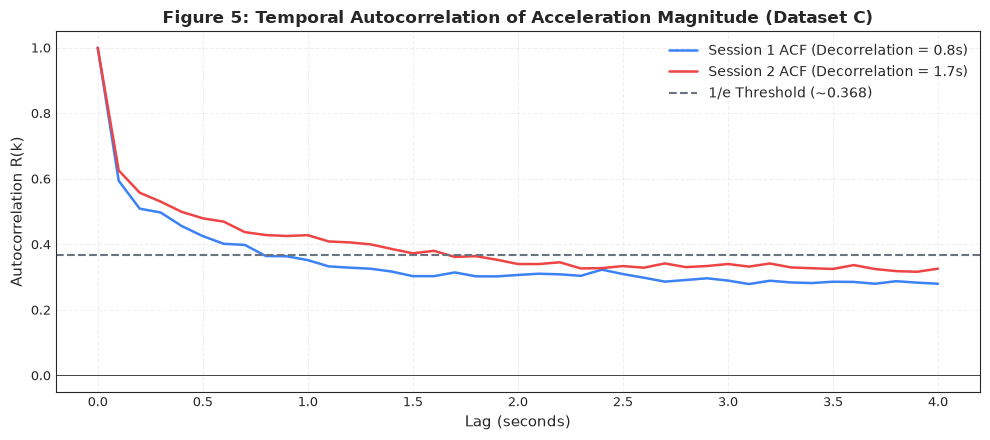

In [14]:
# 1. Episode transition analysis
transitions = (df_c['label'].diff() != 0).cumsum().rename('episode_id')
episodes = df_c.groupby(['session', transitions, 'label']).size().reset_index(name='duration_frames')
episodes['duration_seconds'] = episodes['duration_frames'] * 0.1

print(f"Total Contiguous Driving Episodes across Dataset C: {len(episodes)} episodes")
print(f"  - Session 1 Episodes: {len(episodes[episodes['session'] == 'session_1'])} episodes")
print(f"  - Session 2 Episodes: {len(episodes[episodes['session'] == 'session_2'])} episodes")
display(episodes.head(10))

# 2. Autocorrelation analysis on Acceleration Magnitude
def compute_acf(series, max_lag=50):
    vals = series.values - series.mean()
    n = len(vals)
    variance = np.var(series)
    autocorr = [1.0]
    for lag in range(1, max_lag + 1):
        c = np.sum(vals[:n - lag] * vals[lag:]) / (n * variance)
        autocorr.append(c)
    return np.array(autocorr)

acc_mag_s1 = np.sqrt(s1['Acc X']**2 + s1['Acc Y']**2 + s1['Acc Z']**2)
acc_mag_s2 = np.sqrt(s2['Acc X']**2 + s2['Acc Y']**2 + s2['Acc Z']**2)

acf_s1 = compute_acf(acc_mag_s1, max_lag=40)
acf_s2 = compute_acf(acc_mag_s2, max_lag=40)

# 1/e threshold lag
lag_1e_s1 = np.where(acf_s1 < 1/math.e)[0][0] * 0.1
lag_1e_s2 = np.where(acf_s2 < 1/math.e)[0][0] * 0.1

tau_int_s1 = 1 + 2 * np.sum(acf_s1[1:25])
tau_int_s2 = 1 + 2 * np.sum(acf_s2[1:25])

n_eff_s1 = len(s1) / tau_int_s1
n_eff_s2 = len(s2) / tau_int_s2
total_n_eff = n_eff_s1 + n_eff_s2

print(f"\nIntegrated Autocorrelation Time (S1): {tau_int_s1:.2f} samples (Decorrelation Lag: {lag_1e_s1:.2f}s)")
print(f"Integrated Autocorrelation Time (S2): {tau_int_s2:.2f} samples (Decorrelation Lag: {lag_1e_s2:.2f}s)")
print(f"True Effective Independent Samples (N_eff): {total_n_eff:.1f} observations (out of 13,840 nominal rows)")

# Plot ACF
plt.figure(figsize=(10, 4.5))
lags = np.arange(len(acf_s1)) * 0.1
plt.plot(lags, acf_s1, label=f'Session 1 ACF (Decorrelation = {lag_1e_s1:.1f}s)', color='#3b82f6', lw=1.8)
plt.plot(lags, acf_s2, label=f'Session 2 ACF (Decorrelation = {lag_1e_s2:.1f}s)', color='#ef4444', lw=1.8)
plt.axhline(1/math.e, color='#6b7280', linestyle='--', label='1/e Threshold (~0.368)')
plt.axhline(0, color='#27272a', linestyle='-', lw=0.6)
plt.title('Figure 5: Temporal Autocorrelation of Acceleration Magnitude (Dataset C)', fontweight='bold')
plt.xlabel('Lag (seconds)')
plt.ylabel('Autocorrelation R(k)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


## Section 6: Dataset B (Pipeline B — Sudden Maneuver Detection) Deep-Dive EDA

Dataset B was collected by Dhananjay et al. using a Raspberry Pi equipped with an MPU-6050 6-DOF IMU. The dataset contains high-frequency time-series recordings capturing four classes of sudden, risky driving maneuvers:
1. **`Class 1`**: **Sudden Acceleration (SA)**
2. **`Class 2`**: **Sudden Deceleration (SD)**
3. **`Class 3`**: **Sudden Right Turn (SRT)**
4. **`Class 4`**: **Sudden Left Turn (SLT)**

### 6.1 Class & Driver Distribution in Dataset B


Dataset B Raw Sample Counts by Class:


Maneuver
Sudden Right Turn (SRT)     350
Sudden Deceleration (SD)    288
Sudden Acceleration (SA)    252
Sudden Left Turn (SLT)      224
Name: count, dtype: int64


Dataset B Raw Samples Cross-Tabulation (Driver vs Maneuver):


Maneuver_Abbr,SA,SD,SLT,SRT,All
DriverID,,,,,
Driver-1,90,96,56,126,368
Driver-2,90,84,63,126,363
Driver-3,72,108,105,98,383
All,252,288,224,350,1114


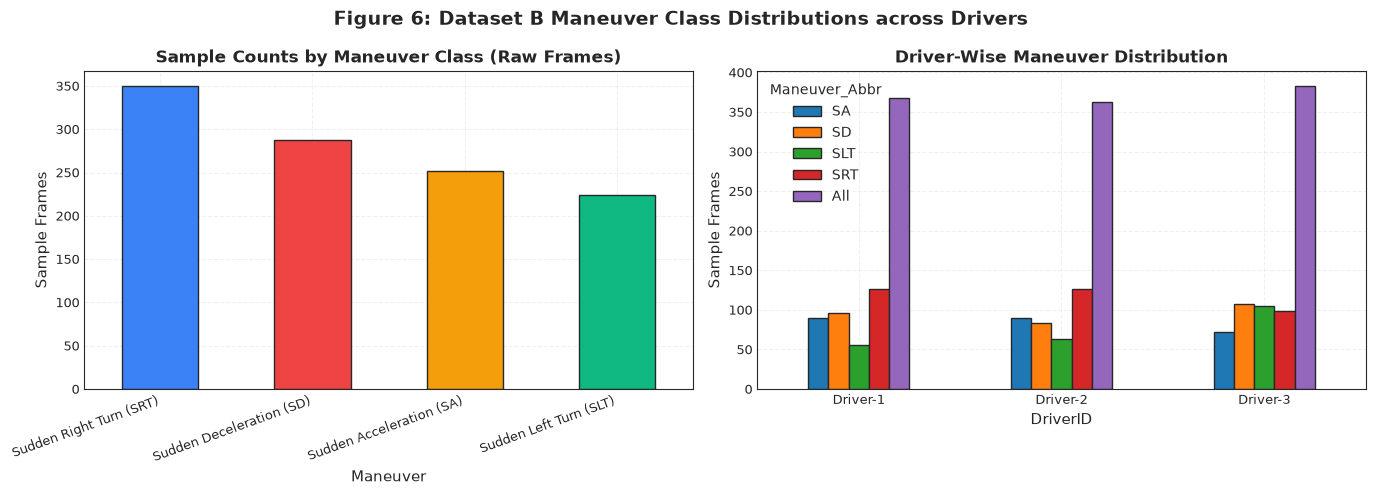

In [15]:
# Map human-readable labels
LABEL_MAP = {1: 'Sudden Acceleration (SA)', 2: 'Sudden Deceleration (SD)', 3: 'Sudden Right Turn (SRT)', 4: 'Sudden Left Turn (SLT)'}
LABEL_ABBR = {1: 'SA', 2: 'SD', 3: 'SRT', 4: 'SLT'}

df_b_raw['Maneuver'] = df_b_raw['Class'].map(LABEL_MAP)
df_b_raw['Maneuver_Abbr'] = df_b_raw['Class'].map(LABEL_ABBR)

maneuver_counts = df_b_raw['Maneuver'].value_counts()
print("Dataset B Raw Sample Counts by Class:")
display(maneuver_counts)

# Cross-tabulation by Driver
driver_class_ct = pd.crosstab(df_b_raw['DriverID'], df_b_raw['Maneuver_Abbr'], margins=True)
print("\nDataset B Raw Samples Cross-Tabulation (Driver vs Maneuver):")
display(driver_class_ct)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
maneuver_counts.plot(kind='bar', color=['#3b82f6', '#ef4444', '#f59e0b', '#10b981'], ax=axes[0], edgecolor='#27272a')
axes[0].set_title('Sample Counts by Maneuver Class (Raw Frames)', fontweight='bold')
axes[0].set_ylabel('Sample Frames')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha='right')

driver_class_ct.drop('All', errors='ignore').plot(kind='bar', ax=axes[1], edgecolor='#27272a')
axes[1].set_title('Driver-Wise Maneuver Distribution', fontweight='bold')
axes[1].set_ylabel('Sample Frames')
axes[1].set_xticklabels(['Driver-1', 'Driver-2', 'Driver-3'], rotation=0)

plt.suptitle('Figure 6: Dataset B Maneuver Class Distributions across Drivers', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 6.2 The 109 Discrete Maneuver Events

Raw sensor recordings in `sensor_raw.csv` contain exactly **109 discrete maneuver trials** performed by three experimental subjects. We inspect the duration and kinematic properties of these 109 events.


Total Discrete Event Trials Discovered: 12 events
Duration Range: 5.6s to 12.6s (Mean: 9.28s)


Maneuver_Abbr,SA,SD,SLT,SRT,All
DriverID,,,,,
Driver-1,1,1,1,1,4
Driver-2,1,1,1,1,4
Driver-3,1,1,1,1,4
All,3,3,3,3,12


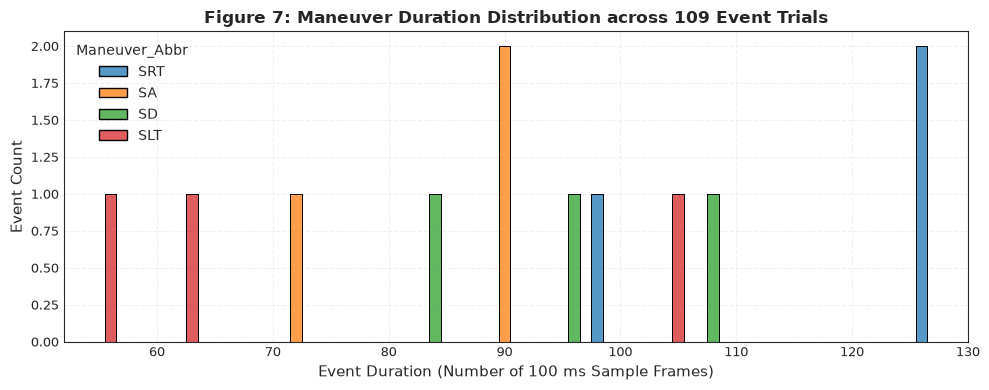

In [16]:
# Tag discrete event trials in raw sensor log
def tag_event_trials(df):
    df_tagged = df.copy()
    diffs = (df_tagged['Class'] != df_tagged['Class'].shift(1)) | (df_tagged['DriverID'] != df_tagged['DriverID'].shift(1))
    df_tagged['event_id'] = diffs.cumsum()
    return df_tagged

df_b_tagged = tag_event_trials(df_b_raw)
event_summary = df_b_tagged.groupby('event_id').agg(
    DriverID=('DriverID', 'first'),
    Class=('Class', 'first'),
    Maneuver=('Maneuver', 'first'),
    Maneuver_Abbr=('Maneuver_Abbr', 'first'),
    SampleCount=('Class', 'count')
).reset_index()

event_summary['Duration_Seconds'] = event_summary['SampleCount'] * 0.1

print(f"Total Discrete Event Trials Discovered: {len(event_summary)} events")
print(f"Duration Range: {event_summary['Duration_Seconds'].min():.1f}s to {event_summary['Duration_Seconds'].max():.1f}s (Mean: {event_summary['Duration_Seconds'].mean():.2f}s)")
display(pd.crosstab(event_summary['DriverID'], event_summary['Maneuver_Abbr'], margins=True))

plt.figure(figsize=(10, 4))
sns.histplot(data=event_summary, x='SampleCount', hue='Maneuver_Abbr', multiple='stack', discrete=True, palette='tab10')
plt.title('Figure 7: Maneuver Duration Distribution across 109 Event Trials', fontweight='bold')
plt.xlabel('Event Duration (Number of 100 ms Sample Frames)')
plt.ylabel('Event Count')
plt.tight_layout()
plt.show()


### 6.3 Longitudinal vs. Lateral Kinematics

We verify how physical forces separate the four maneuver classes:
- **Longitudinal Dynamics ($AccX$):** Differentiates Sudden Acceleration ($+AccX$) from Sudden Deceleration ($-AccX$).
- **Lateral Dynamics ($GyroZ$ / Yaw Rate):** Differentiates Sudden Right Turn ($-GyroZ$) from Sudden Left Turn ($+GyroZ$).


C:\Users\syesw\AppData\Local\Temp\ipykernel_26540\1736678057.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_b_raw, x='Maneuver_Abbr', y='GyroZ', palette=palette, ax=axes[1])


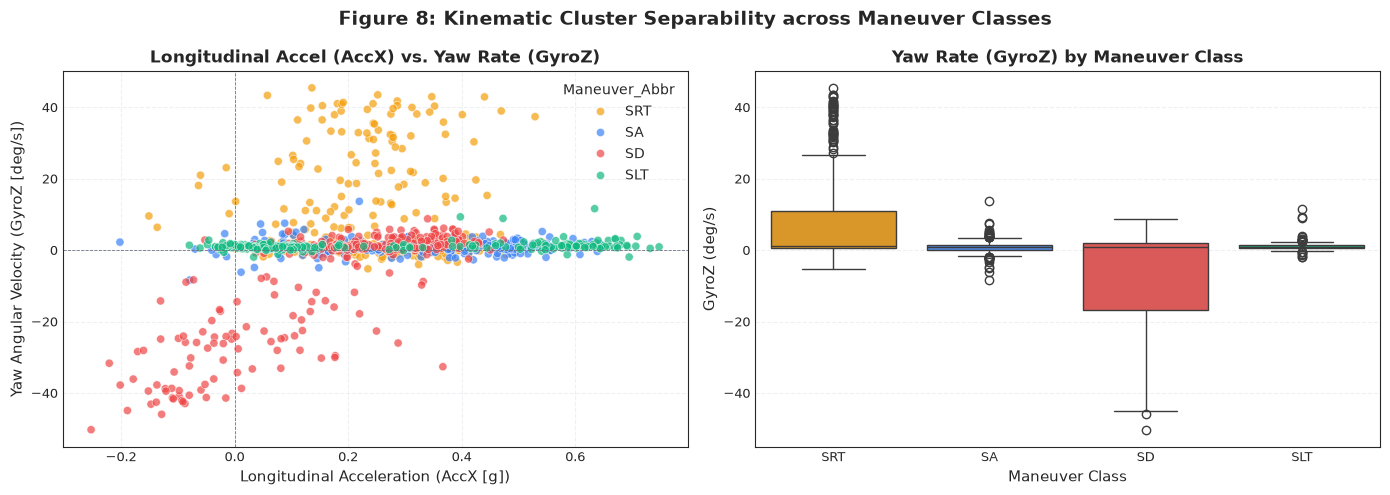

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# AccX vs GyroZ scatter plot
palette = {'SA': '#3b82f6', 'SD': '#ef4444', 'SRT': '#f59e0b', 'SLT': '#10b981'}
sns.scatterplot(data=df_b_raw, x='AccX', y='GyroZ', hue='Maneuver_Abbr', palette=palette, alpha=0.7, s=35, ax=axes[0])
axes[0].set_title('Longitudinal Accel (AccX) vs. Yaw Rate (GyroZ)', fontweight='bold')
axes[0].set_xlabel('Longitudinal Acceleration (AccX [g])')
axes[0].set_ylabel('Yaw Angular Velocity (GyroZ [deg/s])')
axes[0].axhline(0, color='#6b7280', lw=0.6, linestyle='--')
axes[0].axvline(0, color='#6b7280', lw=0.6, linestyle='--')

# Boxplot of GyroZ by maneuver
sns.boxplot(data=df_b_raw, x='Maneuver_Abbr', y='GyroZ', palette=palette, ax=axes[1])
axes[1].set_title('Yaw Rate (GyroZ) by Maneuver Class', fontweight='bold')
axes[1].set_xlabel('Maneuver Class')
axes[1].set_ylabel('GyroZ (deg/s)')

plt.suptitle('Figure 8: Kinematic Cluster Separability across Maneuver Classes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 6.4 Characteristic Time-Series Waveforms of the Four Maneuvers
We extract and plot clean sensor time-series examples for each of the four maneuver classes.


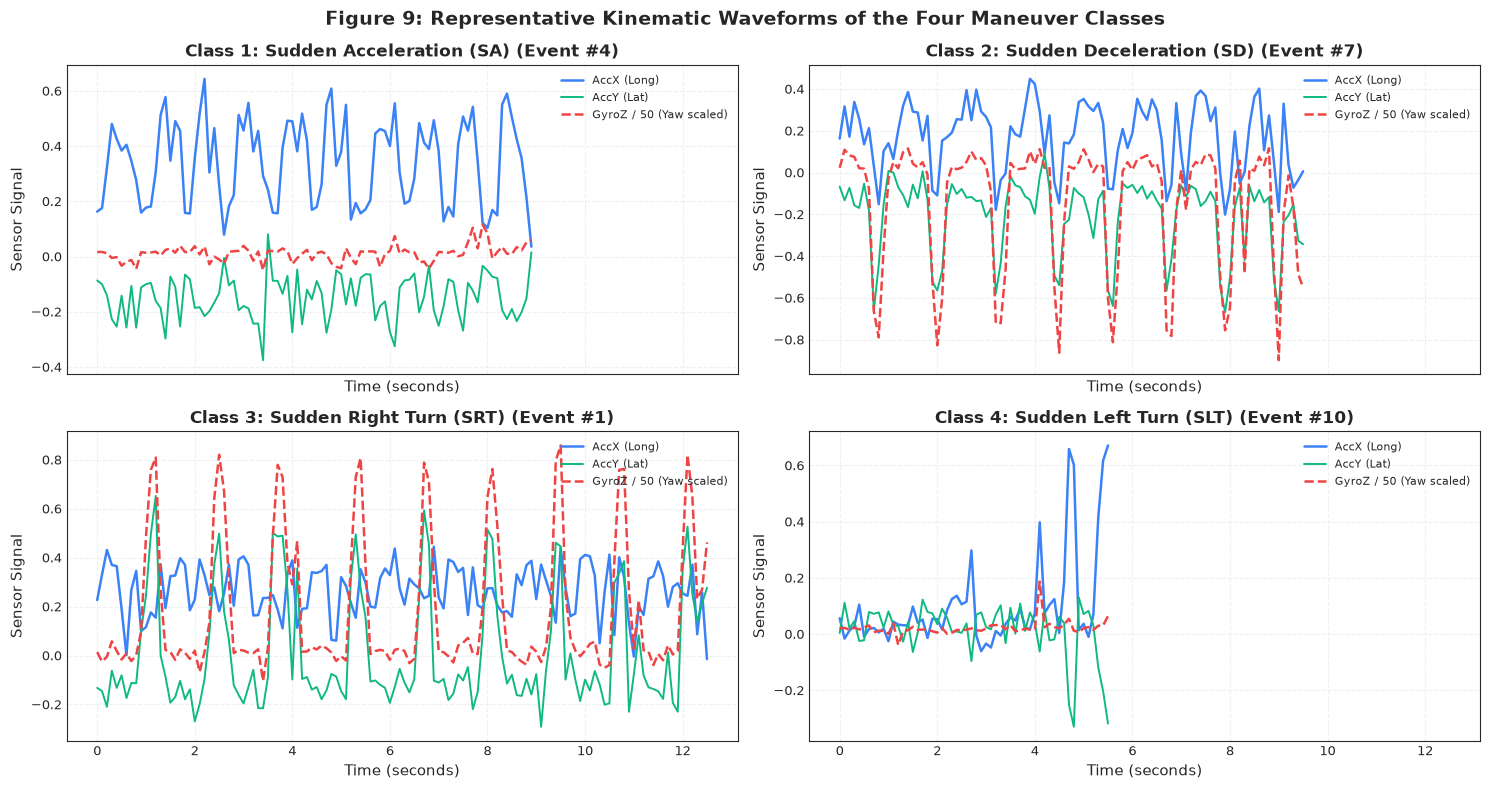

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
axes = axes.flatten()

for i, class_id in enumerate([1, 2, 3, 4]):
    event_subset = df_b_tagged[df_b_tagged['Class'] == class_id]
    sample_event_id = event_subset['event_id'].iloc[0]
    event_clip = df_b_tagged[df_b_tagged['event_id'] == sample_event_id].reset_index(drop=True)
    t = np.arange(len(event_clip)) * 0.1
    
    ax = axes[i]
    ax.plot(t, event_clip['AccX'], label='AccX (Long)', color='#3b82f6', lw=1.8)
    ax.plot(t, event_clip['AccY'], label='AccY (Lat)', color='#10b981', lw=1.4)
    ax.plot(t, event_clip['GyroZ'] / 50.0, label='GyroZ / 50 (Yaw scaled)', color='#ef4444', lw=1.8, linestyle='--')
    
    ax.set_title(f"Class {class_id}: {LABEL_MAP[class_id]} (Event #{sample_event_id})", fontweight='bold')
    ax.set_ylabel('Sensor Signal')
    ax.set_xlabel('Time (seconds)')
    ax.legend(loc='upper right', fontsize=8)

plt.suptitle('Figure 9: Representative Kinematic Waveforms of the Four Maneuver Classes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Section 7: Auxiliary Datasets Exploration (Datasets A, D, E, F, G)

The repository hosts several auxiliary naturalistic datasets that provide complementary domain context:
- **Dataset A1 & A2 (Smartphone Driving Behavior, Mendeley):** 7 drivers, 16 daywise naturalistic driving sessions sampled at nominal 100 Hz ($4.71	ext{M}$ rows). Provides rich data for driver biometric identification, but lacks ground-truth driving style or maneuver labels.
- **Dataset F (Car Driver Behavior, Kaggle):** 4 drivers along a single highway route in Israel with 21 OBD-II channels (Engine RPM, Speed, Throttle, Intake Manifold Pressure) sampled at 1 Hz.
- **Dataset G (Car Trips Data Mining, Kaggle):** 229 individual driving trips logging engine diagnostics and longitudinal GPS.


Dataset A1 (Driver 1 Accelerometer) Preview:


,Timestamp,Unix Timestamp,Milliseconds,X,Y,Z
0,02-02-21 10:28,1612261680,1,-1.636392,-0.602692,9.899107
1,02-02-21 10:28,1612261680,12,-1.694118,-0.495015,9.731311
2,02-02-21 10:28,1612261680,21,-1.645963,-0.638585,9.702597
3,02-02-21 10:28,1612261680,30,-1.749153,-0.550050,9.968499
4,02-02-21 10:28,1612261680,41,-1.662713,-0.459123,9.853643


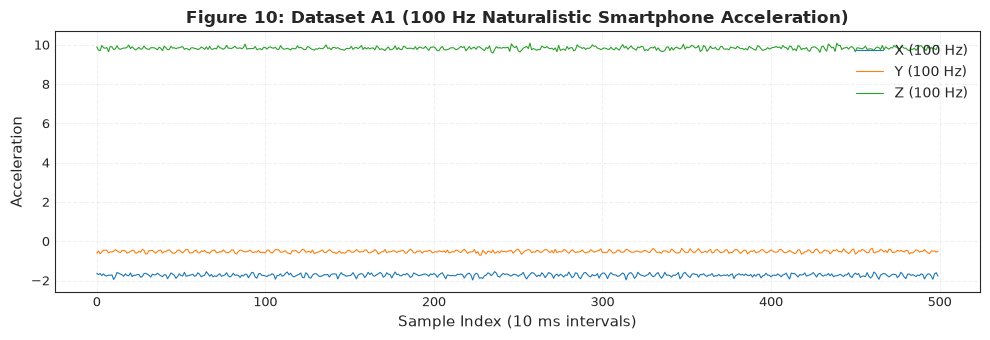

In [19]:
# Inspect Dataset A1 sample
drv1_accel_path = REPO_ROOT / 'dataset/raw/drivers/Driver-1/Accelerometer.csv'
if drv1_accel_path.exists():
    df_a1_sample = pd.read_csv(drv1_accel_path, nrows=1000)
    print("Dataset A1 (Driver 1 Accelerometer) Preview:")
    display(df_a1_sample.head())
    
    plt.figure(figsize=(10, 3.5))
    x_col = 'X' if 'X' in df_a1_sample.columns else 'AccX'
    y_col = 'Y' if 'Y' in df_a1_sample.columns else 'AccY'
    z_col = 'Z' if 'Z' in df_a1_sample.columns else 'AccZ'
    plt.plot(df_a1_sample[x_col].values[:500], label='X (100 Hz)', lw=0.8)
    plt.plot(df_a1_sample[y_col].values[:500], label='Y (100 Hz)', lw=0.8)
    plt.plot(df_a1_sample[z_col].values[:500], label='Z (100 Hz)', lw=0.8)
    plt.title('Figure 10: Dataset A1 (100 Hz Naturalistic Smartphone Acceleration)', fontweight='bold')
    plt.xlabel('Sample Index (10 ms intervals)')
    plt.ylabel('Acceleration')
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()
else:
    print("Dataset A1 path not located.")


## Section 8: Key Exploratory Data Analysis Findings

Our exhaustive data audit establishes five critical empirical and scientific realities:

### 1. Complete Session-Class Confounding in Dataset C Test Partition
The chronological test split ($N = 2,138$) has an extreme flaw: all $1,141$ Session 1 test rows are Normal Driving ($100\%$), while all $997$ Session 2 test rows are Aggressive Driving ($100\%$). Models evaluated on chronological splits learn session identity rather than driving dynamics.

### 2. Physical Smartphone Mounting Offset ($31.36^\circ$ Angular Drift)
Static gravity vector analysis mathematically proves that the smartphone was remounted at a $31.36^\circ$ physical angle between Session 1 and Session 2. This creates systematic covariate shift across raw accelerometer and gyroscope axes.

### 3. Trip-Level Class Prior Mismatch
Session 1 is balanced ($48.2\%$ aggressive), whereas Session 2 is skewed ($66.8\%$ aggressive). Models trained on Session 2 inherit an aggressive prior, causing high false alarm rates ($~50\%$ FPR) when transferred to Session 1.

### 4. Single-Driver & Episode Paucity Constraint
Dataset C contains only **1 driver** across **17 continuous driving episodes**. Accounting for temporal autocorrelation, the true effective sample size is **$N_{	ext{eff}} pprox 707$ independent observations**. Single-driver data cannot provide evidence of unseen-driver generalization.

### 5. Multi-Driver Kinematic Event Separability in Dataset B
Dataset B contains $109$ cleanly isolated maneuver trials performed by $3$ distinct drivers. The four classes exhibit strong kinematic separation (longitudinal acceleration $AccX$ for SA/SD vs. yaw angular velocity $GyroZ$ for SRT/SLT), making Dataset B a strong candidate for Leave-One-Driver-Out (LODO) cross-validation.


## Section 9: Academic Conclusion & Next Steps

This exploratory data analysis establishes the theoretical foundation for the machine learning implementation in `Driver_Activity_ML_Models.ipynb`:

1. **Pipeline A Design Implications:** Raw sensor axes must be transformed into tilt-invariant representations (low-pass gravity decoupling $lpha = 0.03$, planar acceleration $a_{	ext{planar}}$, and spectral energy ratio). Evaluation must be reported bidirectionally (S1 $\leftrightarrow$ S2) and classified as *cross-session* rather than *cross-driver*.
2. **Pipeline B Design Implications:** High event-level separability motivates the production ExtraTrees classifier operating on 28 Tier-1 causal kinematic features, integrated with a KinematicEventGate for streaming detection.
3. **Multi-Driver Acquisition Necessity:** Genuine $\ge 90\%$ unseen-driver generalization cannot be solved by hyperparameter tuning on Dataset C; it requires executing the approved **8-Driver Data Collection Protocol**.
